# 18. Two ways to render the same frame

[Course plan](../../README.md)

Five colored splats sit on white. The upper-left corner is almost empty, yet the renderer from lesson 14 still evaluates all five splats at every pixel. A sideways camera move shifts the empty space as well. Which work can be skipped depends on the current view.


In [1]:
%matplotlib inline
from pathlib import Path
import sys
for folder in (Path.cwd(), *Path.cwd().parents):
    if (folder / "reconstruction.py").is_file():
        sys.path.insert(0, str(folder))
        break
import json
import numpy as np
import matplotlib.pyplot as plt
from reconstruction import *
from reconstruction_demos import photo_capture, tiles_figure, rays_figure, view_figure, error_figure, controls, damage
lang = 'en'


## What belongs in a cell

Cutting the image into squares gives us *tiles*. Pale cells on the list map are nearly empty. Darker blue cells intersect more splats. Cells along the border can be shorter or narrower. Changing the tile size changes the number of pairs to test while preserving the pixels. Tightening a splat’s cutoff changes the image itself.


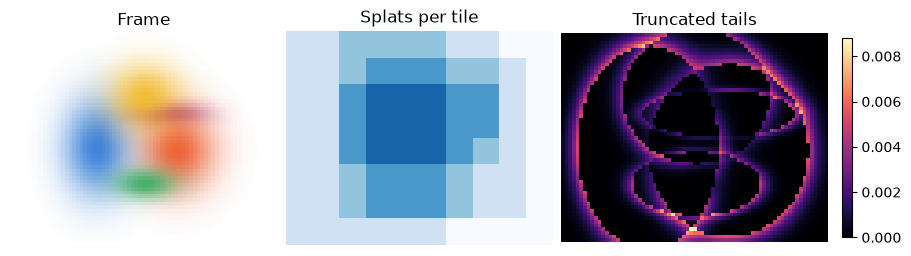

In [2]:
display(tiles_figure(lang=lang))
plt.close()
controls(lambda tile, k, angle: tiles_figure(int(tile), k, angle, lang),
         tile=[8, 4, 16, 32], k=(1., 4., .1, 3.), angle=(-45, 45, 1, 0))


### One object in memory, several addresses on the screen

The previous lesson counted Gaussians. This lesson introduces a different counter which often reads much higher. There are only five objects in space, each with one 3D center. Projection turns its center and shape into a screen footprint. One footprint can cross several screen cells. Each cell gets a short entry saying which object reaches it. The object was never cloned and the scene acquired no extra material. A list describes the current frame. After the camera moves, an old entry may correspond to empty space.

The pixel renderer in lesson 14 starts with “how much red, green and blue reached this location?” A tiled renderer starts a step earlier. Which objects are worth asking about in this part of the picture? Even for a pixel far from the splat, the earlier program subtracted coordinates, measured distance in the stretched local axes, evaluated an exponential, multiplied by opacity and updated the color. All of that work can go toward a value that looks white once rounded for display.

There are two separate decisions here. First comes a distance beyond which a contribution may be set to zero. That changes the footprint we have asked to draw. Then, for an already chosen boundary, we can gather candidates in advance. That changes how the chosen frame is evaluated. A visual check that two pictures look similar can easily mix up these choices. We will have three reference images. One retains infinite tails, one tests all five splats with truncation, and one draws that same truncated model using lists. Each pairwise comparison answers a different question.

## Where a soft splat ends

Strictly speaking, it never does. On a bell centered at 9 with width 2, sample 13 is $(13-9)/2=2$ widths from the center. Squaring 2 gives 4. Dividing by −2 gives −2, and the exponential turns this into $e^{-2}\approx0.1353$. At three widths the weight is still positive, $e^{-9/2}\approx0.0111$. With opacity 0.8, alpha at that boundary is about $0.8\cdot0.0111\approx0.0089$.

An ellipse has two displacements. Suppose the projected center is $m=(9,6)$ and the horizontal and vertical widths are 2 and 1 pixels. At $p=(12,7)$ the offsets are 3 and 1 pixels. Squared distance in units of the splat’s own widths is

$$
q=(3/2)^2+(1/1)^2=2.25+1=3.25.
$$

With cutoff $k=2$, this passes the test $q\le k^2=4$. Its weight is $e^{-3.25/2}\approx0.197$. For a rotated ellipse, lesson 13 gives $q=(p-m)^T S^{-1}(p-m)$, with $S$ the screen covariance in squared pixels. Its inverse removes the units of scale. Both $q$ and $k$ are dimensionless. Both renderers set the weight to zero outside this boundary.


In [3]:
q = (3/2)**2 + (1/1)**2
print("q =", q, "weight =", np.exp(-q/2))
assert q < 2**2 and np.exp(-9/2) < .012


q = 3.25 weight = 0.19691167520419406


### A boundary, a box, and a few extra tests

The small example appears on a pixel grid below. Dots mark the integer centers that pass the exact test. Orange marks the two-width contour. The dashed box is used when preparing tile lists. Its upper left pixel is $(5,4)$. Relative to the center it is two widths left and two widths up. Squared distance is $(-2)^2+(-2)^2=8$. The box covers 9 columns and 5 rows, or 45 pixel centers, whereas only 25 pass the ellipse test. The other 20 are the price of an easy bounding calculation. A pixel can safely fail a later test. Rejecting a needed pixel early would lose its contribution for good.

The chosen boundary condition is $q\le4$, including equality. The extreme points $(5,6)$ and $(13,6)$ therefore still get nonzero weight. The first allowed integer coordinate comes from rounding the left edge **up**, and the last from rounding the right edge **down**. Moving the center 0.2 pixels right gives the horizontal interval $[5.2,13.2]$. Integer centers run from 6 through 13. The tile range must also intersect the actual screen. A negative column cannot become an image pixel.

A rotated long axis usually runs diagonally while tiles remain aligned with the screen. The box width therefore needs the variance along the screen horizontal. Suppose the native scales are 2 and 1 pixels and both axes turn by 45°. The horizontal projections of those scales have lengths $2/\sqrt2$ and $1/\sqrt2$. Adding squares gives $S_{xx}=4/2+1/2=2.5$. The two-width boundary reaches $2\sqrt{2.5}\approx3.16$ pixels to either side. Equal horizontal and vertical bounds at this angle give a square box around a **slanted, elongated** footprint. Evaluating the shape inside still takes the full matrix, including its cross term.

pixel centers: box = 45 ellipse = 25


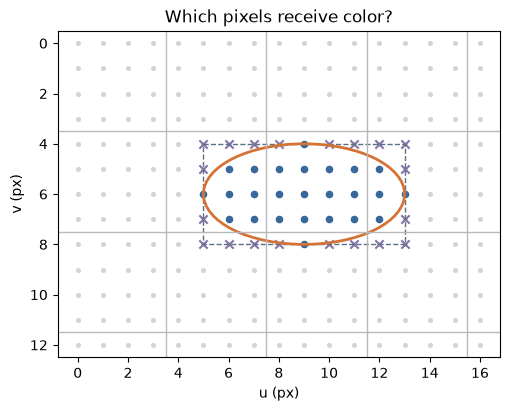

In [4]:
from matplotlib.patches import Ellipse, Rectangle
yy, xx = np.mgrid[0:13, 0:17]
q_grid = ((xx-9)/2)**2+(yy-6)**2
inside = q_grid <= 4
box = (abs(xx-9)<=4) & (abs(yy-6)<=2)
assert np.all(~inside | box)
print("pixel centers: box =", int(box.sum()), "ellipse =", int(inside.sum()))

fig, ax = plt.subplots(figsize=(7.2, 4), constrained_layout=True)
ax.scatter(xx, yy, s=7, color=".83")
ax.scatter(xx[box & ~inside], yy[box & ~inside], marker="x", color="#8675a8")
ax.scatter(xx[inside], yy[inside], color="#38679a", s=20)
ax.add_patch(Rectangle((5,4), 8,4, fill=False, linestyle="--", color="#5c7182"))
ax.add_patch(Ellipse((9,6),8,4,fill=False,edgecolor="#d57236",lw=2))
for edge in (3.5,7.5,11.5,15.5): ax.axvline(edge,c=".72",lw=1)
for edge in (3.5,7.5,11.5): ax.axhline(edge,c=".72",lw=1)
ax.set(xlabel="u (px)",ylabel="v (px)",aspect="equal",ylim=(12.5,-.5),
       title="Какие пиксели получат цвет?" if lang=="ru" else "Which pixels receive color?")
plt.show()

## From an ellipse to a tile list

At two widths the same splat reaches from $9-2\cdot2=5$ to $9+2\cdot2=13$ horizontally and from $6-2\cdot1=4$ to 8 vertically. That rectangle encloses the ellipse. A corner sample can lie in the rectangle and still fail $q\le4$.

With 4-pixel tiles, columns 0–3 belong to tile 0 and columns 4–7 to tile 1. Integer division by 4 gives the tile index. Our rectangle reaches tiles 1, 2, 3 horizontally and 1, 2 vertically. One Gaussian gets $3\cdot2=6$ references. Its shape and color are stored once. For a rotated covariance the bounding half-width is $k\sqrt{S_{xx}}$, the half-height $k\sqrt{S_{yy}}$. These diagonals are variances along the **screen** axes. The square root brings the units back to pixels.

The depth test drops centers behind the near plane. At the edge of the screen, center position alone cannot reject a splat. A center at column −1 with a radius of 3 pixels still reaches column 2. Pixel 0 can receive color while the center lies outside the left boundary. The tile test therefore intersects the footprint rectangle with the image.

Each pixel now needs just one list. The nearest center comes first, then the next center in depth order. A splat receives weight $T\alpha$, where $T$ is the fraction of the ray still available. At $T=0.6$ and $\alpha=0.25$, the color weight is $0.15$ and $0.6(1-0.25)=0.45$ passes through. The order affects the color, so all tiles preserve the same depth ordering.


In [5]:
sc = small_scene()
cam = orbit(0, 73, 57)
slow, brute = finite_render(sc, cam, 73, 57, 8, 3, tiled=False)
fast, bins = finite_render(sc, cam, 73, 57, 8, 3, tiled=True)
print("pairs:", brute["pairs"], "→", bins["pairs"])
print("max |fast − slow|:", np.max(np.abs(fast-slow)))
assert np.allclose(fast, slow, atol=1e-12, rtol=0)


pairs: 20805 → 8688
max |fast − slow|: 0.0


### What would be in a sorted array?

Ordinary Python lists work for the small scene. A paper-and-pencil version makes the GPU pass easier to follow. Suppose a red object R at depth 5 m reaches tiles 0 and 1. Blue B at 2 m reaches only tile 1. Green G at 4 m reaches only tile 0. Projection yields **three** sets of parameters, whereas distributing the addresses yields **four** entries. The entry count is the sum of overlaps rather than the number of objects times the number of tiles.

| Before sorting · tile, depth, object | After sorting |
|---|---|
| 0, 5, R | 0, 4, G |
| 1, 5, R | 0, 5, R |
| 1, 2, B | 1, 2, B |
| 0, 4, G | 1, 5, R |

The key has two parts. Tile IDs are compared first. Within one tile we compare center depths, putting the nearest first. Tile zero takes array positions 0 and 1. Tile one takes 2 and 3. The ranges can be written $[0,2)$ and $[2,4)$. A square bracket includes the left endpoint and a round one excludes the right endpoint. Red appears twice under the same object ID. Its color is read from one parameter row even though two groups of pixels process it.

At a pixel in tile 1, suppose blue has local alpha 0.5 and red has alpha 0.6. The background is white. Blue receives a weight of 0.5, leaving $0.5\cdot0.6=0.3$ for red. The background takes $0.5\cdot0.4=0.2$. Red intensity is $0.3+0.2=0.5$, green $0.2$, and blue $0.5+0.2=0.7$. A list built by merely appending red first and never sorting would make the image redder. Sorting matters for correctness even if every bound is perfect. The depth in the key belongs to the center. A common ordering for the entire tile is an approximation for extended, intersecting objects.

## Counting work and measuring time

With 73 × 57 pixels and five visible splats, the full loop considers 20,805 pixel–splat pairs. A cutoff makes some weights zero, but the distance test has already been paid for. At tile size 8 the lists leave 8,688 pairs to check. One extra candidate in a 64-pixel tile costs 64 tests. Smaller tiles save tests while larger tiles save list entries and setup. Python overhead and array sizes also affect elapsed time. The measurement first renders a warm-up frame, then takes the median of repeated wall-clock timings on this machine.


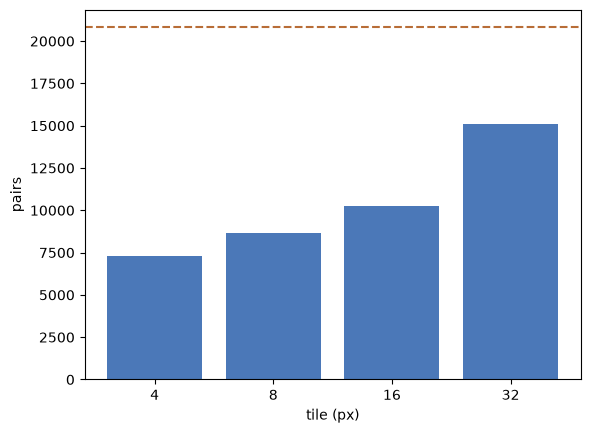

CPU ms: 3.7


In [6]:
sides = [4, 8, 16, 32]
counts = [finite_render(sc, cam, 73, 57, side)[1]["pairs"] for side in sides]
plt.bar([str(s) for s in sides], counts, color="#4b78b8")
plt.axhline(brute["pairs"], color="#b86d37", linestyle="--")
plt.ylabel("pairs"); plt.xlabel("tile (px)"); plt.show()
print("CPU ms:", round(benchmark(lambda: finite_render(sc, cam, 73, 57)), 2))


## How 141 entries turn into 8,688 tests

There is a thin blue strip along the bottom of the list map. Eight does not divide the image dimensions evenly. Nine full tiles fit across, with a one-pixel-wide column left over. Seven fit vertically, followed by a one-pixel-high row. The map has eight rows and ten columns. The interior tile at indices $(3,4)$ contains four splat IDs. Each of its 64 pixels considers four candidates, which costs $64\cdot4=256$ distance tests. On the lower edge, tile $(7,4)$ has eight pixels and one splat. It adds eight tests. The lower-right tile has an empty list. Even its single pixel has no distances to compute.

This gives us a way to count work for any rectangular image. For each tile we multiply **its actual pixel area** by the length of its list, then add up the results. Multiplying all 141 entries by 64 gives 9,024. Those extra 336 tests belong to imaginary pixels beyond the right and bottom boundaries. The first count in the table below is the storage cost in entries. The second measures how often we have to check a distance. Going from 4 to 32 pixels cuts entries by a factor of about 26 while nearly doubling the number of tests. A small tile puts each splat into many lists. With a large tile, even a corner far from the splat gets its ID.

Now tile size stays at 8, and only the splat boundary changes. Each pixel in the error maps gets a color of its own. Of the three RGB differences we take the largest absolute value. Both maps use the same color scale so the cutoffs at one and three widths can be compared. The white background counts too. Dropping a weak blue contribution at the edge reveals more white, even where there are no other splats.

A radius of one width costs 1,728 tests, but the worst channel misses by roughly 0.628 on a scale of one. At three widths we get 8,688 tests and an error of around 0.0125. At four widths tests rise to 12,457 and the largest error falls to 0.00039. That is less than a step of 8-bit color, $1/255\approx0.00392$, in this frame. The number belongs to these five splats, their opacities and this view. A change of scene calls for a fresh comparison against the full Gaussian.

tile | entries | tests | CPU ms
   4 |     464 |  7304 |   10.57


   8 |     141 |  8688 |    3.46
  16 |      46 | 10257 |    1.76
  32 |      18 | 15105 |    2.12
k=1, tests=1728, max |ΔRGB|=0.627549
k=2, tests=4992, max |ΔRGB|=0.182898
k=3, tests=8688, max |ΔRGB|=0.012470
k=4, tests=12457, max |ΔRGB|=0.000391


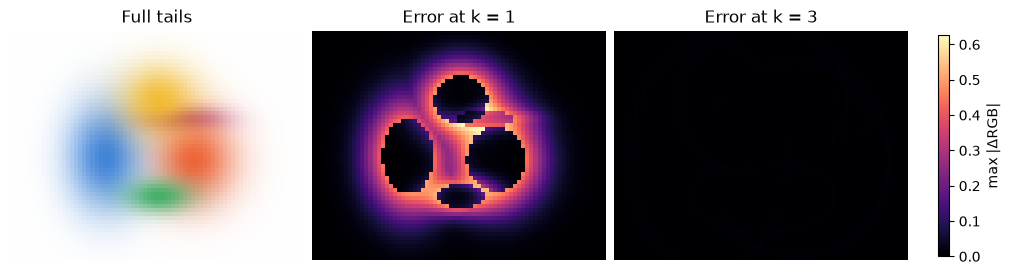

In [7]:
labels = {"ru": ("Полные хвосты", "Ошибка при k = 1", "Ошибка при k = 3", "плитка | записи | проверки | CPU, мс"),
          "en": ("Full tails", "Error at k = 1", "Error at k = 3", "tile | entries | tests | CPU ms")}[lang]
print(labels[3])
for side in [4, 8, 16, 32]:
    _, stats = finite_render(sc, cam, 73, 57, side, 3)
    areas = np.array([[min(side, 57-y)*min(side, 73-x)
                       for x in range(0, 73, side)] for y in range(0, 57, side)])
    assert np.sum(stats["tiles"] * areas) == stats["pairs"]
    ms = benchmark(lambda: finite_render(sc, cam, 73, 57, side, 3), repeats=3)
    print(f"{side:4} | {stats['references']:7} | {stats['pairs']:5} | {ms:7.2f}")
full = render_scene(sc, cam, 73, 57)
errors = {}
for k in [1, 2, 3, 4]:
    cut, stats = finite_render(sc, cam, 73, 57, tile=8, cutoff=k)
    errors[k] = np.max(np.abs(cut-full), axis=2)
    print(f"k={k}, tests={stats['pairs']}, max |ΔRGB|={errors[k].max():.6f}")
fig, axes = plt.subplots(1, 3, figsize=(10, 3), layout="constrained")
axes[0].imshow(full)
for ax, k in zip(axes[1:], [1, 3]):
    im = ax.imshow(errors[k], cmap="magma", vmin=0, vmax=errors[1].max())
fig.colorbar(im, ax=axes[1:].tolist(), shrink=.76, label="max |ΔRGB|")
for ax, title in zip(axes, labels[:3]):
    ax.set_title(title)
    ax.set_axis_off()
plt.show()

## Where the original paper fits

Kerbl, Kopanas, Leimkühler, and Drettakis combine three mechanisms. Trainable 3D Gaussians hold shape and appearance. Density control adds or removes elements. The rasterizer turns the current model into an image quickly. The image loss from earlier lessons sends gradients back through rendering into the parameters. Our teaching implementation exposes the list traversal directly.

The authors’ implementation first culls centers, projects the covariance and computes a screen radius. Each splat–tile pair produces a record carrying a tile ID and depth. After sorting, neighboring records for a tile form one range. A GPU thread block processes a patch of the screen, loading candidate splats into shared memory in batches. Threads shade their pixels in parallel. The reference also includes screen filtering, a small-alpha threshold, an alpha cap and early termination when little transmittance remains. Equality between our arrays tests the two **teaching** paths with one common cutoff. The milliseconds above measure this CPU and this image size.

[Paper and results](https://repo-sam.inria.fr/fungraph/3d-gaussian-splatting/) · [Tile preparation and sorting](https://github.com/graphdeco-inria/diff-gaussian-rasterization/blob/main/cuda_rasterizer/rasterizer_impl.cu) · [Pixel processing on the GPU](https://github.com/graphdeco-inria/diff-gaussian-rasterization/blob/main/cuda_rasterizer/forward.cu)

## What can be shared, and what the backward pass needs

With 256 pixels in a tile, many pixels need the same centers, colors and shapes. In the original GPU rasterizer a block of $16\times16$ threads loads a batch of candidates into the block’s shared memory. Each thread reads these parameters for its own pixel and keeps two numbers for a single channel, the accumulated color and the remaining transmittance $T$. At $T=0.02$, everything farther away can account for at most two hundredths of the total weight. Even replacing a black remainder with white could move the channel by at most 0.02. This is the basis for stopping when a pixel is nearly covered. Once every pixel in the tile has finished, further batches can be skipped altogether.

The backward pass has a different job. Did the front or back splat darken the frame? Take a single gray channel. The near splat has color 0.2, the far one 0.8, and the background is white at 1. Their opacities at this pixel are 0.5 and 0.6. Behind the front splat we see a mixture of $0.6\cdot0.8+0.4\cdot1=0.88$. The final gray is $0.5\cdot0.2+0.5\cdot0.88=0.54$. Adding one hundredth of opacity to the front splat replaces one hundredth of the mixture at 0.88 with its own color of 0.2. The channel changes by $0.01(0.2-0.88)=-0.0068$. Adding the same opacity to the far splat replaces white with 0.8, and only half the change makes it through the front layer. That gives $0.5\cdot0.01(0.8-1)=-0.001$. Even at one pixel the two parameters receive different signals.

In the original backward pass the tile traverses the same list from the far end. Each pixel’s saved transmittance and last contributor help recover the weights needed for derivatives. This avoids storing a separate image for every splat. Screen-space gradients then travel back through projection to scene parameters, as in lesson 16. Tiles help this traversal too. On a frame containing a few enormous overlapping transparent splats, the advantage can disappear. Every tile gets the same IDs, and enough light gets through for distant layers to matter.

## An experiment

What changes when tile size goes from 4 to 32 at the same cutoff? What if tile size stays at 4 but the splat stops at one width?

<details><summary>Worked answer</summary>

The first change alters the lists and test counts. Pixel weights and colors stay equal. The second removes samples whose weights were still around 0.6. Wider gaps show through. The difference from the full bell comes from its new support.

</details>


## Three more small scenes

### One faint tail and ten faint tails

Ten identical black splats over white each give $\alpha=0.01$ at one pixel. How far from white is that pixel when the tails are kept?

<details><summary>Worked answer</summary>

The first splat transmits 0.99 of the white, the second leaves $0.99^2=0.9801$. After ten, $0.99^{10}\approx0.9044$ remains. The splats themselves are black and add nothing to the channel. Dropping all ten gives 1 instead of 0.9044. The error of 0.0956 is much larger than the hundredth due to any one layer. A threshold on individual contributions does not guarantee the same bound for a full frame.

</details>

### A two-pixel border

A 10 × 4 frame is split into 4 × 4 tiles. From left to right, the lists contain two, three and one ID. How many entries are stored, how many pairs get tested, and what would the full loop cost if five splats were visible?

<details><summary>Worked answer</summary>

The lengths sum to $2+3+1=6$ entries. The first two tiles contain 16 pixels each. The last has just $2\cdot4=8$. That gives $16\cdot2+16\cdot3+8\cdot1=88$ tests. Testing every pair would take $10\cdot4\cdot5=200$. Storing six entries saved 112 tests. Milliseconds also depend on how much time goes into constructing and traversing the lists.

</details>

### Five enormous panes

The same five splats grow to cover a 73 × 57 frame and intersect every tile. Center opacity is 0.1. Can the same savings be expected at tile size 8?

<details><summary>Worked answer</summary>

All 80 tiles now hold five IDs. That takes 400 entries and puts the test count back at $73\cdot57\cdot5=20\,805$. The bounding rectangles discarded nobody. Even if every pane reaches peak opacity here, after five layers $0.9^5\approx0.5905$ of the light gets through, far from full coverage. Early termination has little to gain here. For a new scene it makes sense to time preparation and rendering separately before choosing a tile size.

</details>